In [13]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, KFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer, KNNImputer
from sklearn.preprocessing import StandardScaler,OneHotEncoder,OrdinalEncoder,label_binarize
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    roc_auc_score,
    RocCurveDisplay
)
import os
from pathlib import Path
import joblib

In [14]:
MODELS_PATH = Path('../models')
SEED = 10

In [15]:
df = pd.read_csv('../data/processed/cleaned_student_mental_health.csv')

In [16]:
X = df.drop('Mental_Health_Risk',axis=1)
y = df['Mental_Health_Risk']
(X.shape,y.shape)

((1963, 16), (1963,))

In [17]:
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=SEED,stratify=y)

In [18]:
independent_numerical_columns = [
  'Year_of_Study',
  'Study_Hours_Per_Week',
  'GPA',
  'Social_Media_Hours',
  'Screen_Time_Hours',
]
related_numerical_columns = [
  'Age',
  'Sleep_Hours',
  'Financial_Stress',
  'Family_Support',
  'Attendance_Rate'
]
ordinal_columns = {
    'Diet_Quality':['Poor','Average','Good'],
    'Physical_Activity':['Low','Moderate','High']
}
nominal_columns = ['Gender','Part_Time_Job','Previous_Mental_Health_History']

In [19]:
independent_numerical_pipeline = Pipeline([
    ('imputer',SimpleImputer(strategy='mean')),
    ('scaler',StandardScaler())
])
related_numerical_pipeline = Pipeline([
    ('scaler',StandardScaler()),
    ('imputer',KNNImputer(n_neighbors=5,weights='distance')),
])
nominal_pipeline = Pipeline([
    ('imputer',SimpleImputer(strategy='most_frequent')),
    ('encoder',OneHotEncoder(handle_unknown='ignore'))
])
ordinal_pipeline = Pipeline([
    ('imputer',SimpleImputer(strategy='most_frequent')),
    ('encoder',OrdinalEncoder(categories=[ordinal_columns['Diet_Quality'],ordinal_columns['Physical_Activity']]))
])

In [20]:
preprocess = ColumnTransformer([
    ('ind_num',independent_numerical_pipeline,independent_numerical_columns),
    ('rlt_num',related_numerical_pipeline,related_numerical_columns),
    ('nom_cat',nominal_pipeline,nominal_columns),
    ('ord_cat',ordinal_pipeline,[column for column in ordinal_columns])
    # ('ord_cat',ordinal_pipeline,['Diet_Quality','Physical_Activity'])
])

Entraînement et comparaison des modèles

	Logistic Regression
accuracy  : 77.1
precision : 77.0
recall    : 76.97
f1 score  : 76.96


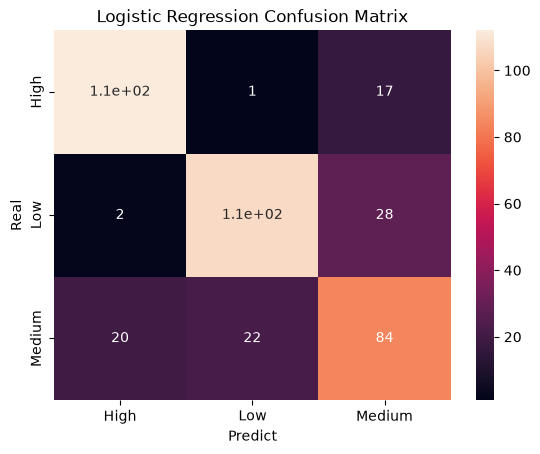

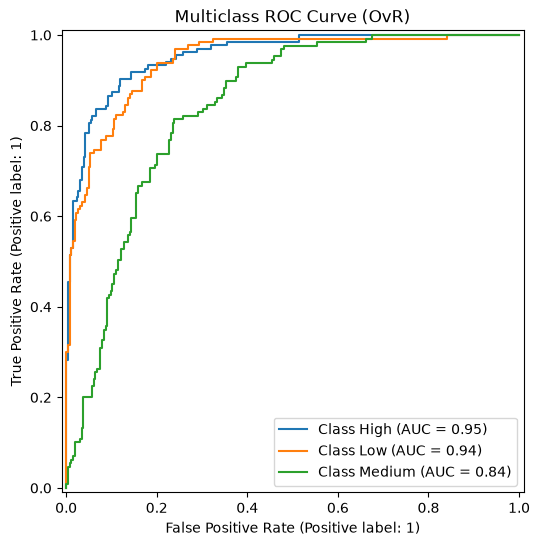

/home/mjseh374/dev_ai/psyche_track/.venv/lib/python3.12/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


	Support Vector Classifier
accuracy  : 72.52
precision : 72.39
recall    : 72.18
f1 score  : 72.27


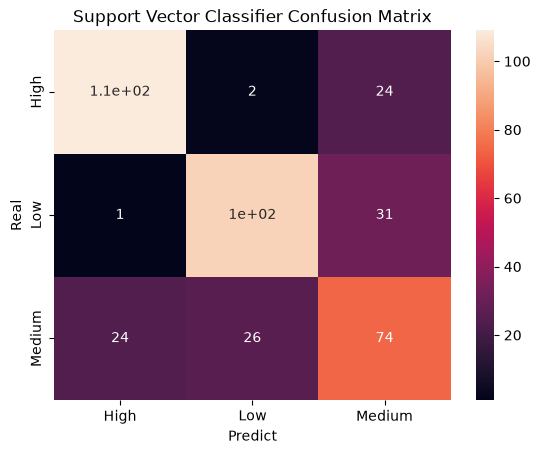

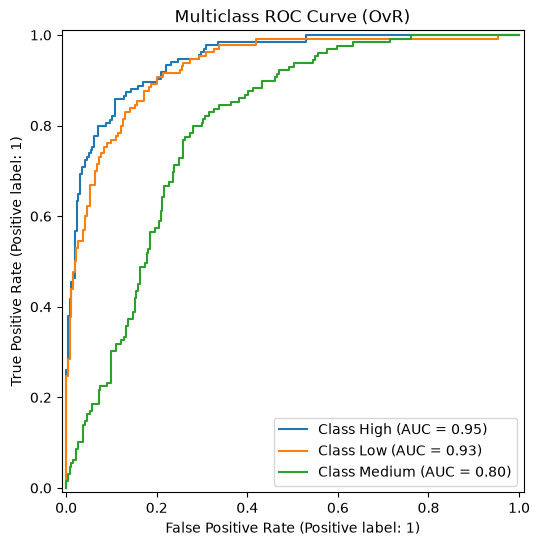

	K-Nearest Neighbors
accuracy  : 59.8
precision : 59.66
recall    : 58.33
f1 score  : 58.77


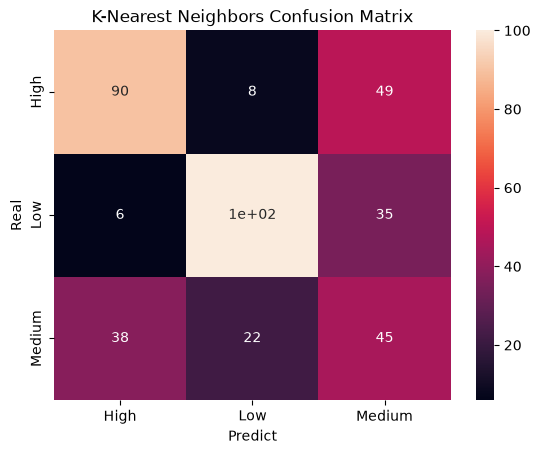

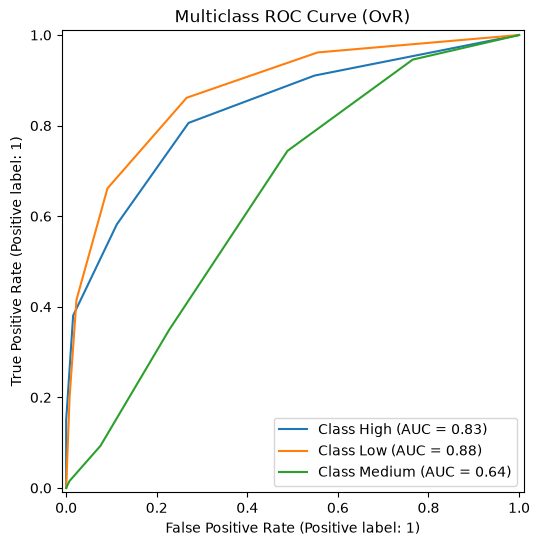

['../models/knn/base/model/base_model.joblib']

In [ ]:
models = {
  'Logistic Regression'      : {'classifier':LogisticRegression(),'path':MODELS_PATH/'logistic_regression/base'},
  'Support Vector Classifier': {'classifier':SVC(probability=True),'path':MODELS_PATH/'svc/base'},
  'K-Nearest Neighbors'      : {'classifier':KNeighborsClassifier(),'path':MODELS_PATH/'knn/base'},
}
models_metrics = []
# X_train,X_val,y_train,y_val = train_test_split(X_train,train_size=0.75,random_state=42,stratify=y)
for name,config in models.items():
  metric_path = config['path']/'metrics'
  model_path = config['path']/'model'
  os.makedirs(metric_path, exist_ok=True)
  os.makedirs(model_path, exist_ok=True)
  pipeline = Pipeline([
      ('preprocess',preprocess),
      ('classifier',config['classifier'])
  ])
  model = pipeline.fit(X_train,y_train)
  y_pred = model.predict(X_test)
  y_proba = model.predict_proba(X_test)
  classes_name = pipeline.classes_
  y_test_bin = label_binarize(y_test, classes=classes_name)
  accuracy = round(accuracy_score(y_pred,y_test)*100,2)
  precision = round(precision_score(y_pred,y_test,average='macro')*100,2)
  recall = round(recall_score(y_pred,y_test,average='macro')*100,2)
  f1 = round(f1_score(y_pred,y_test,average='macro')*100,2)
  auc = round(roc_auc_score(y_test,y_proba,multi_class="ovr",average="macro"),4)
  print('='*30)
  print(f'\t{name}')
  print('='*30)
  print('accuracy  :',accuracy)
  print('precision :',precision)
  print('recall    :',recall)
  print('f1 score  :',f1)
  models_metrics.append({'name':name,'stage':'before','accuracy':accuracy,'precision':precision,'recall':recall,'f1':f1,'auc':auc})
  cm = confusion_matrix(y_pred,y_test,labels=classes_name)
  sns.heatmap(cm,annot=True,xticklabels=classes_name,yticklabels=classes_name)
  plt.title(f'{name} Confusion Matrix')
  plt.xlabel('Predict')
  plt.ylabel('Real')
  plt.savefig(metric_path/'confusion_matrix.png',dpi=300, bbox_inches='tight')
  plt.show()
  _,ax = plt.subplots(figsize=(8,6))
  for i, class_name in enumerate(classes_name):
    RocCurveDisplay.from_predictions(y_test_bin[:, i],y_proba[:, i],name=f"Class {class_name}",ax=ax)
  plt.title("Multiclass ROC Curve (OvR)")
  plt.savefig(metric_path/'roc_curve.png',dpi=300, bbox_inches='tight')
  plt.show()
joblib.dump(model,model_path/'base_model.joblib')

Fitting 5 folds for each of 42 candidates, totalling 210 fits


/home/mjseh374/dev_ai/psyche_track/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/mjseh374/dev_ai/psyche_track/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1407: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
/home/mjseh374/dev_ai/psyche_track/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and u

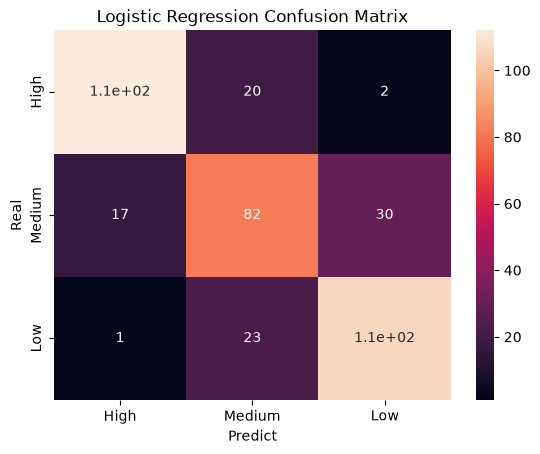

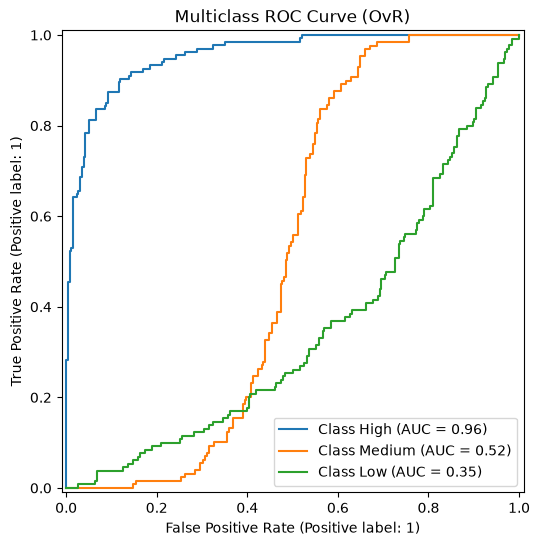

Fitting 5 folds for each of 60 candidates, totalling 300 fits


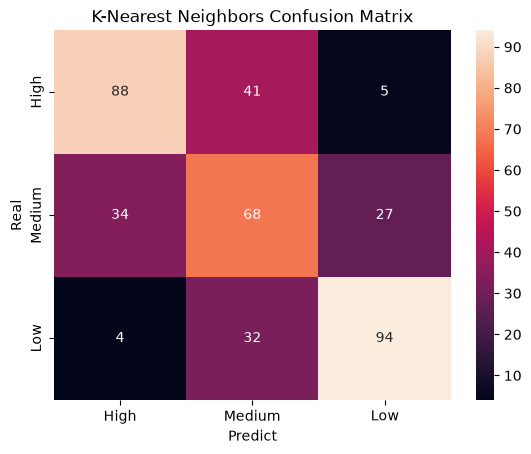

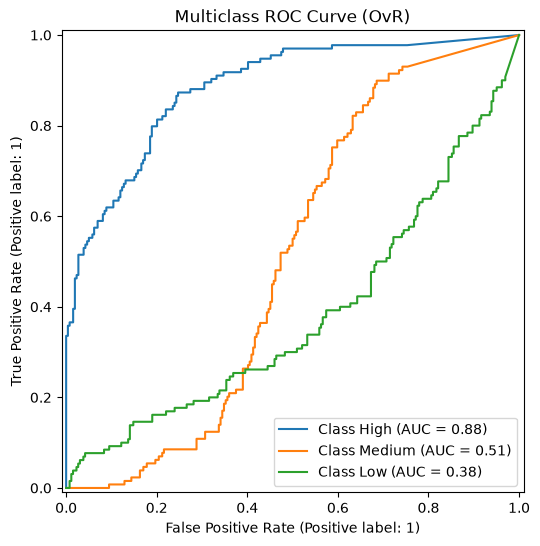

Fitting 5 folds for each of 12 candidates, totalling 60 fits


/home/mjseh374/dev_ai/psyche_track/.venv/lib/python3.12/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/home/mjseh374/dev_ai/psyche_track/.venv/lib/python3.12/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/home/mjseh374/dev_ai/psyche_track/.venv/lib/python3.12/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/home/mjseh374/dev_ai/psyche_track/.venv/lib/python3.12/site-packages/sklearn/svm/_base.py:236

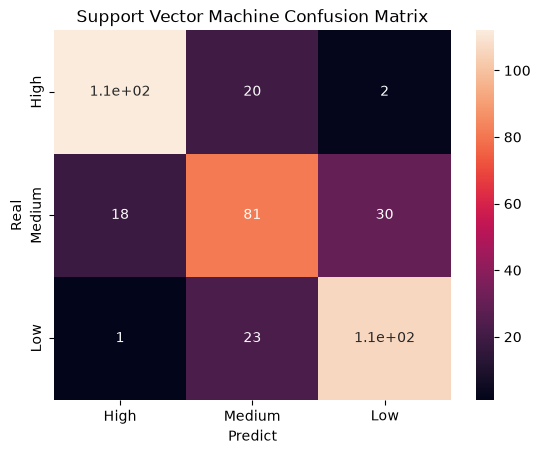

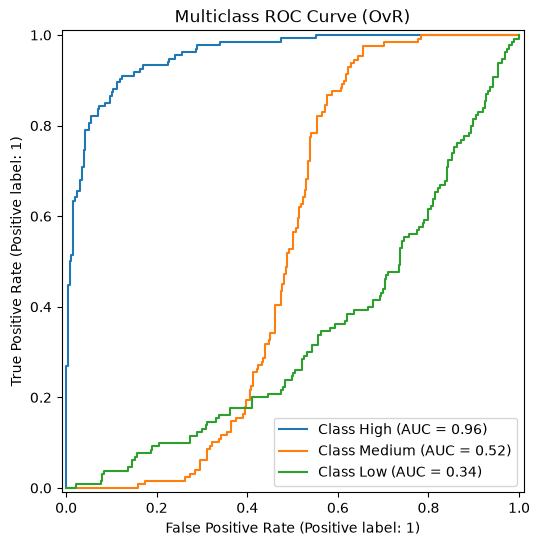

In [ ]:
models = {
    "Logistic Regression": {
        "classifier": LogisticRegression(random_state=SEED),
        "params": {
            'classifier__max_iter': [1000, 2000, 3000],
            'classifier__penalty': ['l1','l2'],
            'classifier__solver': ['saga'],
            'classifier__C': [0.001, 0.01, 0.1, 1, 10, 100, 1000],
        },
        "path": MODELS_PATH/'logistic_regression/fine_tuning'
    },
    "K-Nearest Neighbors": {
        "classifier": KNeighborsClassifier(algorithm='auto'),
        "params": {
            'classifier__n_neighbors': [1, 5, 7, 9, 10],
            'classifier__p': [1, 2],
            'classifier__leaf_size': [20, 50, 100],
            'classifier__weights': ['uniform', 'distance'],
        },
        "path": MODELS_PATH/'knn/fine_tuning'
    },
    "Support Vector Classifier": {
        "classifier": SVC(probability=True,random_state=SEED),
        "params": {
            'classifier__C': [0.1, 1, 10],
            'classifier__kernel': ['linear', 'rbf'],
            'classifier__gamma': ['scale', 'auto']
        },
        "path": MODELS_PATH/'svc/fine_tuning'

    }
}
classes = ['High','Medium', 'Low']
def createPipeline(model):
  return Pipeline([('preprocess',preprocess),('classifier',model)])
import numpy as np
def gridSearch(pipeline,param_grid,cv = KFold(n_splits=5, shuffle=True, random_state=10)):
  return GridSearchCV(estimator=pipeline,param_grid=param_grid,cv=cv,scoring='f1_weighted',n_jobs=-1,verbose=1,error_score='raise')

for name,config in models.items():
  metric_path = config['path']/'metrics'
  model_path = config['path']/'model'
  os.makedirs(metric_path, exist_ok=True)
  os.makedirs(model_path, exist_ok=True)
  pipeline = createPipeline(config['classifier'])
  grid_search = gridSearch(pipeline,config['params'])
  grid_search.fit(X_train,y_train)
  best_model = grid_search.best_estimator_
  y_pred = best_model.predict(X_test)
  y_proba = best_model.predict_proba(X_test)
  y_test_bin = label_binarize(y_test, classes=classes)
  accuracy = round(accuracy_score(y_pred,y_test)*100,2)
  precision = round(precision_score(y_pred,y_test,average='macro')*100,2)
  recall = round(recall_score(y_pred,y_test,average='macro')*100,2)
  f1 = round(f1_score(y_pred,y_test,average='macro')*100,2)
  auc = round(roc_auc_score(y_test,y_proba,multi_class="ovr",average="macro"),4)
  models_metrics.append({'name':name,'stage':'after','accuracy':accuracy,'precision':precision,'recall':recall,'f1':f1,'auc':auc})
  cm = confusion_matrix(y_test,y_pred,labels=classes)
  sns.heatmap(cm,annot=True,xticklabels=classes,yticklabels=classes)
  plt.title(f'{name} Confusion Matrix')
  plt.xlabel('Predict')
  plt.ylabel('Real')
  plt.savefig(metric_path/'confusion_matrix.png',dpi=300, bbox_inches='tight')
  plt.show()
  _,ax = plt.subplots(figsize=(8,6))
  for i, class_name in enumerate(classes):
    RocCurveDisplay.from_predictions(y_test_bin[:, i],y_proba[:, i],name=f"Class {class_name}",ax=ax)
  plt.title("Multiclass ROC Curve (OvR)")
  plt.savefig(metric_path/'roc_curve.png',dpi=300, bbox_inches='tight')
  plt.show()
  joblib.dump(model,model_path/'best_model.joblib')

  # save_model_graphs()
    

In [29]:
models_results = pd.DataFrame(models_metrics)
models_results = models_results.sort_values('name').reset_index().drop('index',axis=1)
models_results

,name,stage,accuracy,precision,recall,f1,auc
0,K-Nearest Neighbors,before,59.80,59.66,58.33,58.77,0.7826
1,K-Nearest Neighbors,after,63.61,63.56,64.22,63.83,0.8116
2,Logistic Regression,before,77.10,77.00,76.97,76.96,0.9129
3,Logistic Regression,after,76.34,76.23,76.19,76.17,0.9130
4,Support Vector Classifier,before,72.52,72.39,72.18,72.27,0.8900
5,Support Vector Machine,after,76.08,75.97,75.88,75.89,0.9138
